# Data Preparation

In [2]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.preprocessing import StandardScaler
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt

In [3]:
# Load dataset
df = pd.read_excel("/content/compressed_features.xlsx")
print("Dataset shape:", df.shape)
print("First 5 rows:\n", df.head())

Dataset shape: (100000, 7)
First 5 rows:
    Lifestyle  Interests  Communication  Responsibility  SocialEngagement  \
0      3.625      3.375          3.125             2.6          2.444444   
1      4.125      3.125          2.375             3.2          2.222222   
2      3.500      2.500          2.750             2.6          2.666667   
3      3.000      3.125          2.875             2.6          2.777778   
4      4.000      3.500          3.000             3.6          2.444444   

   EmotionalStability  Openness  
0            2.833333  2.833333  
1            2.166667  3.166667  
2            2.333333  3.500000  
3            2.833333  2.666667  
4            2.333333  3.000000  


In [4]:
# Handling missing values
print(df.isna().sum())

Lifestyle             3
Interests             3
Communication         3
Responsibility        3
SocialEngagement      3
EmotionalStability    3
Openness              3
dtype: int64


In [5]:
df = df.dropna()
print("dataset shape:", df.shape)

dataset shape: (99997, 7)


In [6]:
# Extract features
X = df.values.astype(float)
print("X shape:", X.shape)

X shape: (99997, 7)


In [7]:
# Scale features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("Scaled X mean:", X_scaled.mean(axis=0))
print("Scaled X std:", X_scaled.std(axis=0))

Scaled X mean: [-2.45570937e-16 -1.06868834e-16 -3.14353537e-16  1.05390860e-15
 -2.52392352e-16 -1.00274799e-15 -1.22558088e-15]
Scaled X std: [1. 1. 1. 1. 1. 1. 1.]


In [8]:
# convert to PyTorch tensor
X_tensor = torch.tensor(X_scaled, dtype=torch.float32)

In [9]:
# create dataset and dataloader
dataset = TensorDataset(X_tensor)
batch_size = 256
dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=True)

print("Number of batches:", len(dataloader))

Number of batches: 391


# Autoencoder

In [10]:
class Autoencoder(nn.Module):
  def __init__(self):
    super(Autoencoder, self).__init__()

    # Encoder
    self.encoder = nn.Sequential(
        nn.Linear(7, 32),
        nn.ReLU(),
        nn.Linear(32, 16),
        nn.ReLU(),
        nn.Linear(16, 5) # lateny layer
    )

    # Decoder
    self.decoder = nn.Sequential(
        nn.Linear(5, 16),
        nn.ReLU(),
        nn.Linear(16, 32),
        nn.ReLU(),
        nn.Linear(32, 7) # reconstruct input
    )

  def forward(self, x):
    z = self.encoder(x) # compress
    x_recon = self.decoder(z) # reconstruct
    return x_recon

## Initialize the Model, Loss, and Optimizer

In [ ]:
model = Autoencoder()
criterion = nn.MSELoss() # mean squared error
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

## Training loop


In [ ]:
num_epochs = 50

for epoch in range(num_epochs):
  total_loss = 0
  for batch in dataloader:
    x = batch[0]

    # Forward pass
    x_recon = model(x)
    loss = criterion(x_recon, x)

    # backpropagation
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    total_loss += loss.item()

  if (epoch + 1) % 10 == 0:
        print(f'Epoch [{epoch+1}/{num_epochs}], Loss: {loss.item():.6f}')


Epoch [10/50], Loss: 0.064934
Epoch [20/50], Loss: 0.069875
Epoch [30/50], Loss: 0.084525
Epoch [40/50], Loss: 0.092636
Epoch [50/50], Loss: 0.069531


## Loss seems to be unstable. We'll do some experiment.


In [11]:
import random
import torch.nn as nn
from torch.utils.data import random_split

In [12]:
# reproducibility
seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)

In [13]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [14]:
print(device)

cpu


We train on 95% of the data and test reconstruction on the other 5%.
If the **validation loss** keeps going down, it means the model is learning general structure.
If it starts **rising while training loss keeps dropping**, it means we're **overfitting**: memorizing instead of learning patterns.

In [15]:
# small validation split (e.g. 5% val) to check for overfitting
val_frac = 0.05
n = len(X_tensor)
n_val = int(n * val_frac)
n_train = n - n_val
train_ds, val_ds = random_split(TensorDataset(X_tensor), [n_train, n_val])

In [16]:
batch_size = 256

train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)

# validation is not shuffled since it's only used for evaluation.
val_loader = DataLoader(val_ds, batch_size=batch_size, shuffle=False)

In [17]:
model = Autoencoder().to(device)

# lower learning rate for stability
lr = 1e-4
optimizer = torch.optim.Adam(model.parameters(), lr=lr)

This schedular monitors validation loss; If the validation loss stop imporving for several epochs (`patience=8`), it automatically reduces the learning rate by half (`factor=0.5`)

In [18]:
# scheduler (ReduceLROnPlateau reacts to val loss)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min',
                                                       factor=0.5, patience=8)

criterion = nn.MSELoss()

### Training loop

In [19]:
num_epochs = 100
print_every = 10
train_losses = []
val_losses = []

# helper to compute average loss on a loader
# It will tell us how well the model is reconstructing unseen data after each epoch.
def eval_loss(loader):
    model.eval()
    total = 0.0
    count = 0
    with torch.no_grad(): # disabling gradient computation
        for batch in loader:
            x = batch[0].to(device)
            x_recon = model(x)
            loss = criterion(x_recon, x)
            total += loss.item() * x.size(0)
            count += x.size(0)
    return total / count

In [20]:
# train loop with gradient norm monitoring
for epoch in range(num_epochs):
    model.train()
    total_loss = 0.0
    n_samples = 0
    for batch in train_loader:
        x = batch[0].to(device)
        x_recon = model(x)
        loss = criterion(x_recon, x)

        optimizer.zero_grad()
        loss.backward()

        optimizer.step()
        total_loss += loss.item() * x.size(0)
        n_samples += x.size(0)

    avg_train = total_loss / n_samples # mean training loss across all batches
    train_losses.append(avg_train)

    # validation loss
    avg_val = eval_loss(val_loader)
    val_losses.append(avg_val)

    # scheduler step on val loss
    scheduler.step(avg_val)

    if (epoch + 1) % print_every == 0 or epoch == 0:
        print(f"Epoch {epoch+1}/{num_epochs} | train_loss={avg_train:.6f} | val_loss={avg_val:.6f} | lr={optimizer.param_groups[0]['lr']:.2e}")

Epoch 1/100 | train_loss=0.980614 | val_loss=0.918879 | lr=1.00e-04
Epoch 10/100 | train_loss=0.161712 | val_loss=0.162281 | lr=1.00e-04
Epoch 20/100 | train_loss=0.148001 | val_loss=0.149833 | lr=1.00e-04
Epoch 30/100 | train_loss=0.144371 | val_loss=0.146013 | lr=1.00e-04
Epoch 40/100 | train_loss=0.140865 | val_loss=0.141530 | lr=1.00e-04
Epoch 50/100 | train_loss=0.137403 | val_loss=0.138222 | lr=1.00e-04
Epoch 60/100 | train_loss=0.134619 | val_loss=0.135679 | lr=1.00e-04
Epoch 70/100 | train_loss=0.132158 | val_loss=0.133406 | lr=1.00e-04
Epoch 80/100 | train_loss=0.130087 | val_loss=0.131446 | lr=1.00e-04
Epoch 90/100 | train_loss=0.127960 | val_loss=0.129464 | lr=1.00e-04
Epoch 100/100 | train_loss=0.125266 | val_loss=0.127471 | lr=1.00e-04


In [21]:
# after training: gradient norms (last batch)
model.eval()
grad_norms = []
for p in model.parameters():
    if p.grad is not None:
        grad_norms.append(p.grad.detach().cpu().norm().item())
if grad_norms:
    print("Gradient norm stats (min, mean, max):", np.min(grad_norms), np.mean(grad_norms), np.max(grad_norms))
else:
    print("No gradients available (maybe evaluated after optimizer.step).")


Gradient norm stats (min, mean, max): 0.010892373509705067 0.2259666930573682 1.2066477537155151


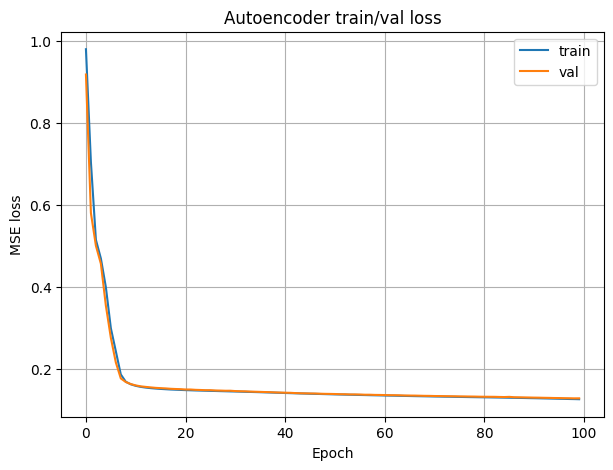

In [22]:
# plot and save
plt.figure(figsize=(7,5))
plt.plot(train_losses, label='train')
plt.plot(val_losses, label='val')
plt.xlabel('Epoch')
plt.ylabel('MSE loss')
plt.yscale('linear')
plt.legend()
plt.grid(True)
plt.title('Autoencoder train/val loss')
plt.savefig('ae_loss_curve.png', dpi=150)
plt.show()


- **Early epochs:** The loss drops steeply in the first 10 epochs which is normal because the model is rapidly learning the basic structure of the data.
- **Middle Phase (10-30 epochs):** After the sharp drop, the losses continue decreasing but more slowly.
- **Later phase (30-100 epochs):** The curves flatten out smoothly, meaning the model has nearly converged. It's not learning much new, and the loss stabilized.

# Extract Embeddings (z)

In [ ]:
model.to(device)
model.eval()

# build a dataloader for your entire dataset (no labels, no shuffle)
